# Data science: giriş


1. NumPy və pandas
2. Statistika
3. matplotlib


## 1. Məlumat və əlamətlər

NumPy massivi eyni tipli ədədlər sütununu saxlayır. Pandas həmin sütunları cədvələ yığır.


In [2]:
import numpy as np
import pandas as pd

# Yaş sütunu həm NumPy massivi, həm də sonra pandas sütunu olacaq.
age = np.array([18, 21, 19, 22])
age


array([18, 21, 19, 22])

## 1.1. Python siyahısı, C++ massivi, ndarray

- Python siyahısı obyektlərə göstəricilər saxlayır və ölçüsünü dəyişə bilir.
- C++ massivi bir tipdən ibarətdir, elementlər yaddaşda ardıcıl durur.
- Ünvan: başlanğıc + i × elementin ölçüsü.
- `ndarray` eyni modeldir: bir `dtype`, ardıcıl bufer.


In [ ]:
import numpy as np
import pandas as pd

# Siyahı ölçüsünü dəyişə bilir və eyni yerdə fərqli tiplər saxlayır.
# Hər element ayrıca Python obyektinə göstəricidir.
scores_list = [70, 85, 90]
scores_list.append("absent")
print("siyahı:", scores_list)

# ndarray bir dtype saxlayır. Elementlər yaddaşda ardıcıl durur.
# C++ tərəfdəki uyğun model:
#   int scores[3] = {70, 85, 90};
#   scores[i] ünvanı: başlanğıc + i * sizeof(int)
# Python-da sizeof rolunu itemsize oynayır.
scores = np.array([70, 85, 90], dtype=np.int32)
print("scores[1] =", scores[1])
print("dtype =", scores.dtype, " itemsize =", scores.itemsize, " nbytes =", scores.nbytes)

# İkiölçülü massiv C++-dakı int table[3][2] cədvəlinə uyğundur.
# Sətir müşahidə, sütun əlamətdir: yaş və bal.
table = np.array(
    [
        [18, 70],
        [21, 85],
        [19, 90],
    ],
    dtype=np.int32,
)
print("table.shape =", table.shape)
print("birinci sətir =", table[0])
print("bütün ballar, sütun 1 =", table[:, 1])

# Massivə element artırmaq köhnə buferi uzatmır, yeni massiv qaytarır.
extended = np.append(scores, 60)
extended


## 1.2. Əlamət ndarray-də durur

Eyni tipli sütun bir buferdir. Toplama, orta və müqayisə Python dövrəsi olmadan gedir.


In [ ]:
import numpy as np
import pandas as pd

age = np.array([18, 21, 19, 22])
score = np.array([70, 85, 90, 60])

# Eyni hesab siyahıda Python dövrəsi tələb edir.
total = 0
for value in score.tolist():
    total += value
print("dövrə ilə cəm =", total)

# Massivdə əməliyyat bütün buferə bir dəfədə tətbiq olunur.
print("mean =", score.mean())
print("age + 1 =", age + 1)
print("80 və yuxarı ballar =", score[score >= 80])

# İki əlamət eyni uzunluqda olanda elementlər cüt-cüt toplanır.
age + score


## 1.3. Series bir sütundur

`Series` indeksdən və qiymətlər massivindən ibarətdir. İndeks sətirin adıdır, mövqe isə 0, 1, 2 sırasıdır.


In [ ]:
import numpy as np
import pandas as pd

# Standart indeks 0, 1, 2, 3 sırasıdır. Bu RangeIndex adlanır.
age_default = pd.Series([18, 21, 19, 22], name="age")
print(age_default)
print("indeks:", age_default.index.tolist())

# İndeks sətirin adıdır. Mövqe isə 0-dan sayılan yerdir.
age_named = pd.Series(
    [18, 21, 19, 22],
    index=["Aysel", "Murad", "Leyla", "Nigar"],
    name="age",
)
print("loc Murad =", age_named.loc["Murad"])
print("iloc 1 =", age_named.iloc[1])

# loc dilimi son adı da daxil edir: Murad, Leyla və Nigar.
print(age_named.loc["Murad":"Nigar"])

# Qiymətlər altda ndarray-dir.
print("to_numpy =", age_named.to_numpy())
age_named


: 

## 1.4. DataFrame cədvəldir

Sətir müşahidədir, sütun əlamətdir. Hər sütun öz `dtype`-ı olan `Series`-dir.


In [ ]:
import numpy as np
import pandas as pd
df = pd.DataFrame(
    {
        "name": ["Aysel", "Murad", "Leyla", "Nigar", "Kamran", "Sevinc", "Elvin", "Aynur"],
        "age": [18, 21, 19, 22, 20, 18, 23, 19],
        "score": [70, 85, 90, 60, 75, 88, 95, 67],
        "hours": [3, 5, 7, 2, 4, 6, 8, 3],
        # Bir boş xana info-da dolu sayın sütundan sütuna dəyişdiyini göstərir.
        "project": [80, 90, 85, np.nan, 70, 88, 92, 75],
    }
)

print("shape =", df.shape)
print(df.dtypes)

# Bir sütunun seçimi Series qaytarır.
score_column = df["score"]
print("score sütunu Series-dir:", isinstance(score_column, pd.Series))

# loc sətiri şərtlə, iloc mövqe ilə götürür.
print("birinci sətir:")
print(df.iloc[0])
print("Leyla-nın balı =", df.loc[df["name"] == "Leyla", "score"].iloc[0])

# Şərt bütün sətirlərdən alt cədvəl kəsir.
df[df["score"] >= 80]


: 

## 1.5. Oxumaq və yazmaq

`read_csv` mətn faylını cədvələ çevirir, `to_csv` onu geri yazır. Excel üçün `openpyxl` lazımdır.


In [ ]:
import numpy as np
import pandas as pd

from pathlib import Path

df = pd.DataFrame(
    {
        "name": ["Aysel", "Murad", "Leyla", "Nigar", "Kamran", "Sevinc", "Elvin", "Aynur"],
        "age": [18, 21, 19, 22, 20, 18, 23, 19],
        "score": [70, 85, 90, 60, 75, 88, 95, 67],
        "hours": [3, 5, 7, 2, 4, 6, 8, 3],
        # Bir boş xana info-da dolu sayın sütundan sütuna dəyişdiyini göstərir.
        "project": [80, 90, 85, np.nan, 70, 88, 92, 75],
    }
)

# Fayllar notebook-un işçi qovşağına düşür.
root = Path.cwd()
csv_path = root / "students.csv"
excel_path = root / "students.xlsx"

df.to_csv(csv_path, index=False)
loaded = pd.read_csv(csv_path)
print("yazıldı:", csv_path.name)
print(loaded.dtypes)
print("boş project sayı =", int(loaded["project"].isna().sum()))

loaded.to_csv(root / "students_out.csv", index=False)

# Excel üçün openpyxl lazımdır. Kitabxana yoxdursa csv nümunəsi yenə işlək qalır.
try:
    loaded.to_excel(excel_path, index=False)
    from_excel = pd.read_excel(excel_path, sheet_name=0)
    from_excel.to_excel(root / "students_out.xlsx", index=False)
    print("excel yazıldı və geri oxundu:", excel_path.name, "->", from_excel.shape)
except ImportError:
    print("Excel nümunəsi ötürülür: openpyxl qurulmayıb (pip install openpyxl).")

loaded.head(3)


## 1.6. head, tail, sample

Üç metod da cədvəlin kiçik hissəsinə baxır. `head` susmaya görə ilk 5 sətri göstərir.


In [4]:
import numpy as np
import pandas as pd
df = pd.DataFrame(
    {
        "name": ["Aysel", "Murad", "Leyla", "Nigar", "Kamran", "Sevinc", "Elvin", "Aynur"],
        "age": [18, 21, 19, 22, 20, 18, 23, 19],
        "score": [70, 85, 90, 60, 75, 88, 95, 67],
        "hours": [3, 5, 7, 2, 4, 6, 8, 3],
        # Bir boş xana info-da dolu sayın sütundan sütuna dəyişdiyini göstərir.
        "project": [80, 90, 85, np.nan, 70, 88, 92, 75],
    }
)

print("head, susmaya görə 5:")
print(df.head())
print("head(2):")
print(df.head(2))
print("tail(2):")
print(df.tail(2))

# random_state eyni iki sətri hər dəfə qaytarır, dərsdə nəticə sabit qalır.
df.sample(2, random_state=0)


head, susmaya görə 5:
     name  age  score  hours  project
0   Aysel   18     70      3     80.0
1   Murad   21     85      5     90.0
2   Leyla   19     90      7     85.0
3   Nigar   22     60      2      NaN
4  Kamran   20     75      4     70.0
head(2):
    name  age  score  hours  project
0  Aysel   18     70      3     80.0
1  Murad   21     85      5     90.0
tail(2):
    name  age  score  hours  project
6  Elvin   23     95      8     92.0
7  Aynur   19     67      3     75.0


,name,age,score,hours,project
6,Elvin,23,95,8,92.0
2,Leyla,19,90,7,85.0


## 1.7. info və describe

`info` quruluşu yoxlayır: ad, `dtype`, dolu xana sayı, yaddaş. `describe` ədədi sütunların yayılmasını göstərir.


In [ ]:
import numpy as np
import pandas as pd
df = pd.DataFrame(
    {
        "name": ["Aysel", "Murad", "Leyla", "Nigar", "Kamran", "Sevinc", "Elvin", "Aynur"],
        "age": [18, 21, 19, 22, 20, 18, 23, 19],
        "score": [70, 85, 90, 60, 75, 88, 95, 67],
        "hours": [3, 5, 7, 2, 4, 6, 8, 3],
        # Bir boş xana info-da dolu sayın sütundan sütuna dəyişdiyini göstərir.
        "project": [80, 90, 85, np.nan, 70, 88, 92, 75],
    }
)

df.info()

# name sütunu ədədi olmadığı üçün describe-a düşmür.
print(df.describe())
print("score.mean() =", df["score"].mean())


## 2. Əsas statistika

Təsadüfi kəmiyyət, orta göstəricilər və paylanma. Seçmə: 70, 85, 90, 85, 60.


In [5]:
import numpy as np
import pandas as pd
score = np.array([70, 85, 90, 85, 60])

# 85 iki dəfə təkrarlanır ki, modanın bir qiyməti olsun.
print("seçmə =", score)
score.mean()


seçmə = [70 85 90 85 60]


np.float64(78.0)

## 2.1. Təsadüfi kəmiyyət

Hər müşahidə kəmiyyətin bir qiymətidir. Sütun həmin kəmiyyətin seçməsidir.


In [ ]:
import numpy as np
import pandas as pd
score = np.array([70, 85, 90, 85, 60])

print("müşahidə sayı =", score.size)
print("bir müşahidə, mövqe 0 =", score[0])

# Yeni müşahidə seçməyə əlavə olunur, kəmiyyətin özü qalır.
np.append(score, 77)


## 2.2. Ədədi orta

Qiymətlərin cəmi onların sayına bölünür. Ucqar qiymət ortanı özünə tərəf çəkir.


In [ ]:
import numpy as np
import pandas as pd
score = np.array([70, 85, 90, 85, 60])

manual_mean = score.sum() / score.size
print("əl ilə orta =", manual_mean)
print("score.mean() =", score.mean())
print("np.mean =", np.mean(score))

# Ucqar qiymət ortanı özünə tərəf çəkir.
with_low = np.append(score, 0)
with_low.mean()


## 2.3. Moda

Ən tez təkrarlanan qiymətdir. NumPy-də ayrıca moda funksiyası yoxdur, onu pandas qaytarır.


In [ ]:
import numpy as np
import pandas as pd
score = np.array([70, 85, 90, 85, 60])

score_series = pd.Series(score)
print("tək moda:")
print(score_series.mode())

# Bir neçə qiymət eyni ən yüksək tezlikdədirsə, mode hamısını qaytarır.
two_modes = pd.Series([70, 70, 90, 90, 60])
two_modes.mode()


## 2.4. Mediana

Sıralanmış seçmənin ortasındakı qiymətdir. Say tək olanda bu, ortadakı elementdir. Say cüt olanda iki ortadakı ədədin ortasıdır.


In [ ]:
import numpy as np
import pandas as pd
score = np.array([70, 85, 90, 85, 60])

# 60, 70, 85, 85, 90 içində ortadakı 85-dir.
print("sıra =", np.sort(score))
print("mediana =", np.median(score))

# Cüt sayda mediana iki ortadakı ədədin ortasıdır: (70 + 85) / 2.
even = np.array([60, 70, 85, 90])
print("cüt seçmənin medianı =", np.median(even))

# Ucqar 0 ortanı 78-dən aşağı salır, mediana ortaya daha az sürüşür.
with_low = np.append(score, 0)
print("0 ilə orta =", with_low.mean(), " mediana =", np.median(with_low))


## 2.5. Dispersiya

Hər fərqin kvadratı toplanır. Seçmə dispersiyasında cəm `n - 1`-ə bölünür. `ddof=1` həmin böləni seçir. Arqument yazılmayanda NumPy `n`-ə bölür.


In [ ]:
import numpy as np
import pandas as pd
score = np.array([70, 85, 90, 85, 60])

centered = score - np.mean(score)
sum_sq = np.sum(centered**2)
sample_var = sum_sq / (score.size - 1)
population_var = sum_sq / score.size
print("fərqlər =", centered)
print("kvadratlar cəmi =", sum_sq)
print("seçmə dispersiyası =", sample_var)
print("np.var ddof=1 =", np.var(score, ddof=1))
print("np.var ddof=0 =", np.var(score, ddof=0))
population_var


## 2.6. Standart kənarlaşma

Dispersiyanın kvadrat köküdür. Ölçü vahidi ilkin kəmiyyətlə eyni qalır.


In [ ]:
import numpy as np
import pandas as pd
score = np.array([70, 85, 90, 85, 60])

sample_std = np.std(score, ddof=1)
sample_var = np.var(score, ddof=1)
print("np.std ddof=1 =", sample_std)
print("kök(dispersiya) =", np.sqrt(sample_var))

# Kiçik kənarlaşma qiymətlərin ortaya yığıldığını göstərir.
tight = np.array([78, 79, 77, 78, 80])
wide = np.array([40, 70, 78, 90, 120])
print("dar seçmə std =", np.std(tight, ddof=1))
print("geniş seçmə std =", np.std(wide, ddof=1))


## 2.7. Bərabər paylanma

Verilmiş aralıqda hər qiymətin şansı eynidir. `uniform(0, 10)` bu aralıqdan seçmə götürür.


In [ ]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(0)

# Böyük seçmənin ortası aralığın ortasına, yəni 5-ə yaxınlaşır.
uniform_small = rng.uniform(0, 10, size=5)
uniform_large = rng.uniform(0, 10, size=10_000)
print("5 qiymət =", uniform_small)
print("min =", uniform_large.min(), " max =", uniform_large.max())
uniform_large.mean()


## 2.8. Normal paylanma

Kütlə mərkəz ətrafında zəng formasındadır. `loc` mərkəzdir, `scale` standart kənarlaşmadır.


In [ ]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(0)

# Böyük seçmədə orta loc-a, std isə scale-ə yaxınlaşır.
normal_small = rng.normal(loc=78, scale=12, size=5)
normal_large = rng.normal(loc=78, scale=12, size=10_000)
print("5 qiymət =", normal_small)
print("orta =", normal_large.mean())
normal_large.std(ddof=1)


## 2.9. Puasson paylanması

Hadisələrin sayını təsvir edir. `lam` orta hadisə sayıdır. Nəticə 0, 1, 2 və sonrakı tam ədədlərdir.


In [ ]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(0)

poisson_small = rng.poisson(lam=3, size=8)
poisson_large = rng.poisson(lam=3, size=10_000)
print("8 qiymət =", poisson_small)
print("unikal qiymətlər =", np.unique(poisson_large))
poisson_large.mean()


## 2.10. Kovariasiya və korrelyasiya

Kovariasiya iki kəmiyyətin birlikdə necə dəyişdiyini göstərir. Korrelyasiya həmin əlaqəni −1 ilə 1 arasına salır. Matrisin diaqonalından kənar xana cütlüyün nəticəsidir.


In [ ]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(0)

# Saat artdıqca bal da artır: müsbət əlaqə.
hours = np.array([2, 4, 5, 7, 9], dtype=float)
score_hours = np.array([50, 65, 70, 85, 95], dtype=float)

cov_matrix = np.cov(hours, score_hours, ddof=1)
corr_matrix = np.corrcoef(hours, score_hours)
print("kovariasiya:")
print(cov_matrix)
print("korrelyasiya:")
print(corr_matrix)
print("cütlüyün korrelyasiyası =", corr_matrix[0, 1])

# Səhv sayı artdıqca bal düşür: mənfi korrelyasiya.
mistakes = np.array([8, 5, 4, 2, 1], dtype=float)
print("səhv və bal =", np.corrcoef(mistakes, score_hours)[0, 1])

# Əlaqəsiz böyük seçmədə korrelyasiya 0-a yaxın olur.
left = rng.normal(size=5_000)
right = rng.normal(size=5_000)
np.corrcoef(left, right)[0, 1]


## 3. matplotlib

`Figure` bütün şəkildir. `Axes` bir koordinat sahəsidir. Qrafik bu sahəyə əlavə olunur.


Matplotlib is building the font cache; this may take a moment.


Text(0.5, 0.98, 'Bir Figure, iki Axes')

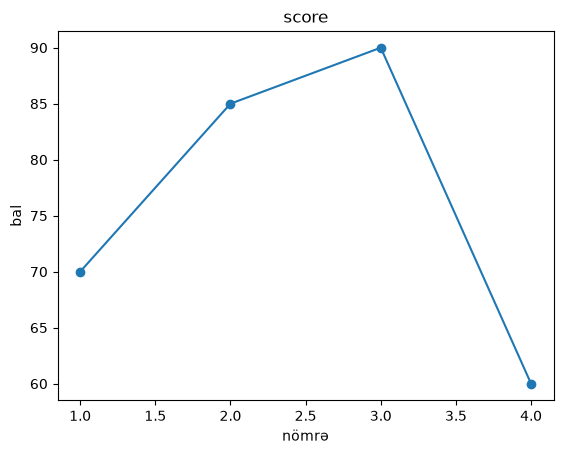

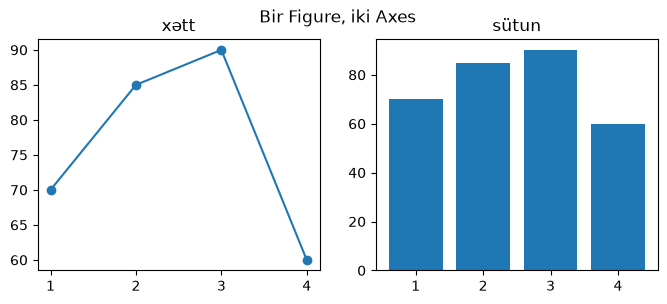

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# subplots həm fiquru, həm də oxu birlikdə qaytarır.
fig, ax = plt.subplots()
ax.plot([1, 2, 3, 4], [70, 85, 90, 60], marker="o")
ax.set_title("score")
ax.set_xlabel("nömrə")
ax.set_ylabel("bal")

# Bir fiqurda iki ox: solda xətt, sağda həmin nöqtələrin sütunları.
fig_two, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].plot([1, 2, 3, 4], [70, 85, 90, 60], marker="o")
axes[0].set_title("xətt")
axes[1].bar([1, 2, 3, 4], [70, 85, 90, 60])
axes[1].set_title("sütun")
fig_two.suptitle("Bir Figure, iki Axes")


## 3.1. Funksiyanın qrafiki

`x` nöqtələrdən ibarət massivdir. `y` həmin nöqtələrdə funksiyanın qiymətidir. `plot` nöqtələri xətlə birləşdirir.


In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

x = np.linspace(-3, 3, 200)
y = x**2

fig, ax = plt.subplots()
ax.plot(x, y, label="y = x²")
ax.plot(x, 2 * x + 3, label="y = 2x + 3")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.set_title("Funksiyaların qrafiki")


## 3.2. Histoqram

Qiymətlər intervallara bölünür, hər intervalın sayı göstərilir. `bins` interval sayıdır.


In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
rng = np.random.default_rng(0)

# Şaquli xətt seçmənin ortasını göstərir.
normal_sample = rng.normal(loc=78, scale=12, size=500)
fig, ax = plt.subplots()
ax.hist(normal_sample, bins=20)
ax.axvline(normal_sample.mean(), color="black", linestyle="--", label="orta")
ax.set_title("Normal seçmənin histoqramı")
ax.set_xlabel("qiymət")
ax.set_ylabel("say")
ax.legend()

# Üç paylanma yan-yana: bərabər, normal, Puasson.
uniform_sample = rng.uniform(0, 10, size=500)
poisson_sample = rng.poisson(lam=3, size=500)
fig_dist, dist_axes = plt.subplots(1, 3, figsize=(10, 3))
dist_axes[0].hist(uniform_sample, bins=15)
dist_axes[0].set_title("Bərabər")
dist_axes[1].hist(normal_sample, bins=15)
dist_axes[1].set_title("Normal")
dist_axes[2].hist(poisson_sample, bins=range(0, 12))
dist_axes[2].set_title("Puasson")
fig_dist.suptitle("Paylanmaların histoqramı")


## 3.3. Dairəvi diaqram

Dilimin bucağı hissənin bütündəki payıdır. `autopct` faizi dilimin üzərinə yazır.


In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

labels = ["A", "B", "C"]
sizes = [12, 7, 5]

fig, ax = plt.subplots()
ax.pie(sizes, labels=labels, autopct="%1.0f%%", startangle=90)
ax.set_title("Qiymət qruplarının payı")


## 3.4. Box-plot

Qutu birinci kvartildən üçüncü kvartilə qədərdir. Ortadakı xətt mediandır. Bığlardan kənar nöqtələr ayrıca düşür.


count      7.000000
mean      75.714286
std       20.499710
min       40.000000
25%       65.000000
50%       85.000000
75%       87.500000
max      100.000000
dtype: float64


Text(0, 0.5, 'bal')

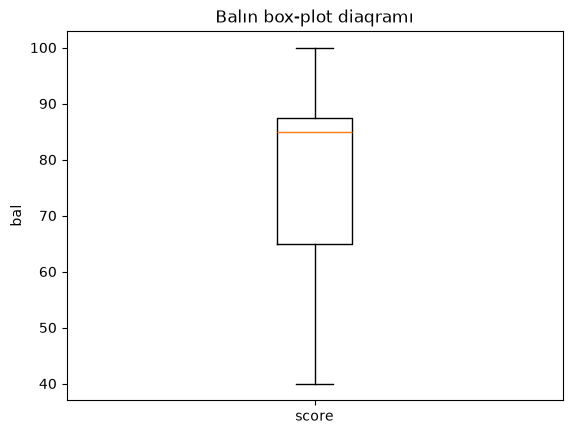

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

box_score = np.array([70, 85, 90, 85, 60, 100, 40])
print(pd.Series(box_score).describe())

fig, ax = plt.subplots()
ax.boxplot(box_score, tick_labels=["score"])
ax.set_title("Balın box-plot diaqramı")
ax.set_ylabel("bal")


## 3.5. Nöqtəli diaqram

Hər nöqtə bir müşahidədir. Üfüqi ox bir kəmiyyətdir, şaquli ox o biridir. Nöqtələr yuxarı-sağa gedəndə korrelyasiya müsbətdir.


In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

hours = np.array([2, 4, 5, 7, 9], dtype=float)
score_hours = np.array([50, 65, 70, 85, 95], dtype=float)
print("korrelyasiya =", np.corrcoef(hours, score_hours)[0, 1])

fig, ax = plt.subplots()
ax.scatter(hours, score_hours)
ax.set_xlabel("hours")
ax.set_ylabel("score")
ax.set_title("Saat və bal")


## 3.6. Sütun diaqramı

Hər sütun bir kateqoriyanın qiymətidir. Hündürlük ədədi göstərir.


In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

names = ["Aysel", "Murad", "Leyla", "Nigar"]
bar_score = [70, 85, 90, 60]

fig, ax = plt.subplots()
bars = ax.bar(names, bar_score)
ax.bar_label(bars)
ax.set_ylabel("bal")
ax.set_title("Tələbələrin balı")
ax.set_ylim(0, 100)
